# TASK AIS-3 -- spatial-temporal matching of AIS vessels to backtracked candidates

**Scope: RAW MATCHING EVIDENCE ONLY.** Uses `iste.ais_matching` (new, does not
import/modify `iste.phase3_ais` (T35) or `iste.phase3_composite` (T36)) to match
the AIS-2 validated event-window+AOI vessel tracks against the EXISTING June-2019
Phase 3 candidate output (`result/hotspots.json`, T17's own already-produced
records, read-only). **Does NOT rank vessels, does NOT compute an AIS evidence
score, and does NOT modify Stage III, T27-T39, or any existing candidate/cluster/
uncertainty output.**

T36/T37 ARE recomputed once below, using their own existing unmodified functions,
purely to attach each candidate's already-established `cluster_id` (a read-only,
reproducible reuse -- not a modification -- of already-approved code, exactly the
same call sequence `T_june2019_phase3_pipeline.ipynb` already used).

In [1]:
import os, sys, time, json as _json
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from iste.ais_matching import (
    haversine_distance_km, load_phase3_candidates, analyze_timestamp_alignment,
    compute_vessel_candidate_matches, summarize_vessel_matches, analyze_vessel_track,
    DEFAULT_DISTANCE_BINS_KM, DEFAULT_TIME_TOLERANCE_HOURS, DEFAULT_CLOSE_ENCOUNTER_DISTANCE_KM,
)

RESULT_DIR = os.path.join(REPO_ROOT, "result")
os.makedirs(RESULT_DIR, exist_ok=True)

T_OBS = pd.Timestamp("2019-06-14T20:35:58Z")
T72 = pd.Timestamp("2019-06-11T20:35:58Z")
print(f"frozen event window: T72={T72} .. T0={T_OBS}")

frozen event window: T72=2019-06-11 20:35:58+00:00 .. T0=2019-06-14 20:35:58+00:00


## 1. Recompute T36/T37 (read-only reuse, unmodified) to attach `cluster_id` to each candidate

In [2]:
from iste.ensemble_run import EnsembleRunRecords
from iste.analysis_grid import generate_analysis_grid
from iste.candidate_extraction import CandidateExtractionConfig, find_candidate_peaks
from iste.kdtree_neighborhood import build_particle_neighborhood_index
from iste.particle_query import query_particle_slice
from iste.support_features import SupportFeatureConfig, compute_support_map
from iste.phase3_composite import DEFAULT_WEIGHTS, compute_source_scores_for_candidates
from iste.phase3_clustering import DEFAULT_EPS_M, cluster_candidates

history_path = os.path.join(RESULT_DIR, "stage3_particle_history_june2019.npz")
cached = np.load(history_path, allow_pickle=True)
def _none_if_empty(arr):
    return None if arr.size == 0 else arr
records = EnsembleRunRecords(
    particle_id=cached["particle_id"], forcing_member_id=cached["forcing_member_id"],
    observation_pixel_id=cached["observation_pixel_id"], timestamp=cached["timestamp"],
    lat=cached["lat"], lon=cached["lon"], log_weight=cached["log_weight"], valid=cached["valid"],
    death_time=_none_if_empty(cached["death_time"]), death_lat=_none_if_empty(cached["death_lat"]),
    death_lon=_none_if_empty(cached["death_lon"]), death_reason=_none_if_empty(cached["death_reason"]),
    survival_mark=_none_if_empty(cached["survival_mark"]),
)
t_obs_np = np.datetime64(np.max(records.timestamp), "ns")
grid = generate_analysis_grid(t_obs_np, window_hours=72.0, interval_hours=1.0)
historical_timestamps = grid[1:]

spill_data = _json.load(open(os.path.join(REPO_ROOT, "data", "database_payload.json"), encoding="utf-8"))
spill = next(s for s in spill_data["spills"] if s["image_filename"] == "ow-0008.jpg")
obs_bbox = spill["bounding_box"]
valid_mask = records.valid
lat_min = min(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].min()))
lat_max = max(obs_bbox["upper_left"]["lat"], obs_bbox["bottom_right"]["lat"], float(records.lat[valid_mask].max()))
lon_min = min(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].min()))
lon_max = max(obs_bbox["upper_left"]["lon"], obs_bbox["bottom_right"]["lon"], float(records.lon[valid_mask].max()))
PAD_DEG = 0.03
support_lat_grid = np.arange(lat_min - PAD_DEG, lat_max + PAD_DEG, 0.003)
support_lon_grid = np.arange(lon_min - PAD_DEG, lon_max + PAD_DEG, 0.003)
NEIGHBORHOOD_RADIUS_M = 1000.0
support_config = SupportFeatureConfig()
extraction_config = CandidateExtractionConfig(peak_neighborhood_cells=5, min_separation_m=1500.0, core_radius_m=1000.0)
lon_mesh, lat_mesh = np.meshgrid(support_lon_grid, support_lat_grid)

t0 = time.time()
all_candidates = []
support_grids_by_t_s = {}
for t_s in historical_timestamps:
    slice_ = query_particle_slice(records, t_s)
    index = build_particle_neighborhood_index(slice_)
    support_map = compute_support_map(index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config)
    support_grids_by_t_s[np.datetime64(t_s, "ns")] = np.array([sf.support for sf in support_map]).reshape(len(support_lat_grid), len(support_lon_grid))
    all_candidates.extend(find_candidate_peaks(support_map, support_lat_grid, support_lon_grid, t_s, config=extraction_config))
default_scores = compute_source_scores_for_candidates(
    records, all_candidates, support_grids_by_t_s, neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M, weights=DEFAULT_WEIGHTS,
)
clusters = cluster_candidates(all_candidates, default_scores, eps_m=DEFAULT_EPS_M)
t1 = time.time()
print(f"recomputed {len(all_candidates)} candidates, T36 scores, {len(clusters)} T37 clusters in {t1-t0:.1f}s (read-only reuse)")

cluster_lookup = {}
for cl in clusters:
    for cid in cl.member_candidate_ids:
        cluster_lookup[cid] = cl.cluster_id
print(f"built cluster_id lookup for {len(cluster_lookup)} candidates")

recomputed 271 candidates, T36 scores, 4 T37 clusters in 202.7s (read-only reuse)
built cluster_id lookup for 271 candidates


## 2. Load Phase 3 candidates (requirement 1) + AIS-2 validated tracks

In [3]:
hotspots_path = os.path.join(RESULT_DIR, "hotspots.json")
candidates_df = load_phase3_candidates(hotspots_path, cluster_lookup=cluster_lookup)
print(f"loaded {len(candidates_df)} Phase 3 candidates from {hotspots_path}")
print(f"distinct candidate timestamps: {candidates_df['t_s'].nunique()}")
print(candidates_df.head(3).to_string())

ais_path = os.path.join(RESULT_DIR, "AIS_vessel_tracks_event_window.csv")
ais_df = pd.read_csv(ais_path)
ais_df["timestamp"] = pd.to_datetime(ais_df["timestamp"], utc=True)
print(f"loaded {len(ais_df)} AIS observations ({ais_df['mmsi'].nunique()} vessels) from {ais_path}")

loaded 271 Phase 3 candidates from C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result\hotspots.json
distinct candidate timestamps: 72
                  candidate_id                       t_s        lat        lon  support_score   cluster_id
0  2019-06-11T20:35:58_cand000 2019-06-11 20:35:58+00:00  34.382546  35.000462     931.249119  cluster0000
1  2019-06-11T20:35:58_cand001 2019-06-11 20:35:58+00:00  34.343546  35.009462     350.557253  cluster0000
2  2019-06-11T20:35:58_cand002 2019-06-11 20:35:58+00:00  34.409546  35.072462      15.878826  cluster0000
loaded 10150 AIS observations (264 vessels) from C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result\AIS_vessel_tracks_event_window.csv


## 3. Timestamp alignment (requirement 2) -- BEFORE any matching

In [4]:
alignment = analyze_timestamp_alignment(candidates_df["t_s"], ais_df["timestamp"])
print(f"n_candidate_timestamps                    : {alignment.n_candidate_timestamps}")
print(f"n_distinct_ais_timestamps                  : {alignment.n_distinct_ais_timestamps}")
print(f"n_ais_timestamps_exactly_on_candidate_grid  : {alignment.n_ais_timestamps_exactly_on_candidate_grid}")
print(f"fraction_ais_timestamps_on_grid             : {alignment.fraction_ais_timestamps_on_grid:.3f}")
print(f"typical_offset_seconds (median)             : {alignment.typical_offset_seconds:.1f}")
print(f"max_offset_seconds                          : {alignment.max_offset_seconds:.1f}")
print()
print("interpretation: AIS observation timestamps and Phase 3 candidate checkpoint "
      "timestamps are compared directly above -- this determines whether an 'exact' "
      "match (requirement 3) is even structurally common, before any matching is attempted.")

n_candidate_timestamps                    : 72
n_distinct_ais_timestamps                  : 73
n_ais_timestamps_exactly_on_candidate_grid  : 72
fraction_ais_timestamps_on_grid             : 0.986
typical_offset_seconds (median)             : 0.0
max_offset_seconds                          : 3600.0

interpretation: AIS observation timestamps and Phase 3 candidate checkpoint timestamps are compared directly above -- this determines whether an 'exact' match (requirement 3) is even structurally common, before any matching is attempted.


## 4. Compute vessel-candidate matches (requirements 3-5) -- exact / +/-1h / +/-2h

In [5]:
print(f"DEFAULT_TIME_TOLERANCE_HOURS (widest computed) = {DEFAULT_TIME_TOLERANCE_HOURS}")
print(f"DEFAULT_DISTANCE_BINS_KM (diagnostic bins only, NOT ranking rules) = {DEFAULT_DISTANCE_BINS_KM}")

t0 = time.time()
matches_df = compute_vessel_candidate_matches(candidates_df, ais_df, max_time_tolerance_hours=DEFAULT_TIME_TOLERANCE_HOURS)
t1 = time.time()
print(f"computed {len(matches_df)} (candidate, AIS observation) pairs within +/-{DEFAULT_TIME_TOLERANCE_HOURS}h in {t1-t0:.1f}s")

n_exact = int(matches_df["is_exact"].sum())
n_1h = int(matches_df["is_within_1h"].sum())
n_2h = int(matches_df["is_within_2h"].sum())
print(f"pairs satisfying is_exact    : {n_exact}")
print(f"pairs satisfying is_within_1h: {n_1h}")
print(f"pairs satisfying is_within_2h: {n_2h}  (== total, by construction)")
assert n_2h == len(matches_df)

DEFAULT_TIME_TOLERANCE_HOURS (widest computed) = 2.0
DEFAULT_DISTANCE_BINS_KM (diagnostic bins only, NOT ranking rules) = (1.0, 2.0, 5.0, 10.0)


computed 185366 (candidate, AIS observation) pairs within +/-2.0h in 7.8s
pairs satisfying is_exact    : 37819
pairs satisfying is_within_1h: 112119
pairs satisfying is_within_2h: 185366  (== total, by construction)


## 5. Distance + time-difference distributions

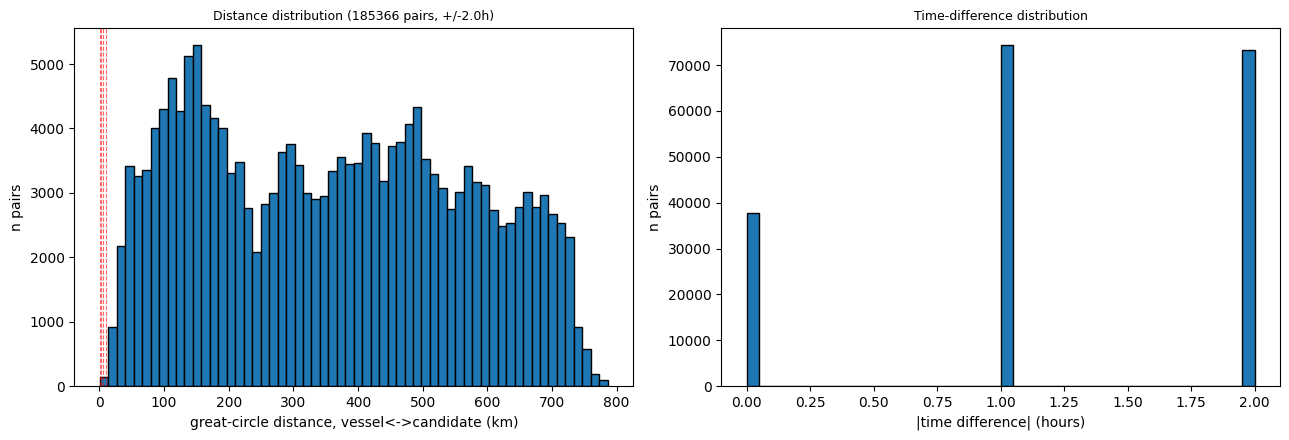

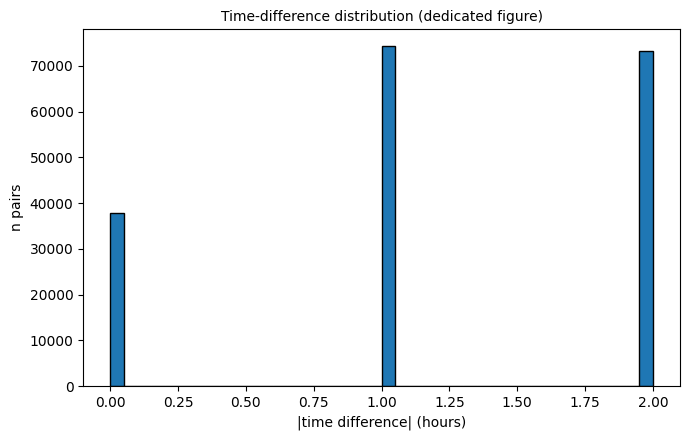

distance_km percentiles -- p10=96.50 p25=174.09 median=361.99 p75=527.70 p90=653.57 p95=694.98 p99=733.37
pairs with distance <= 1 km: 3 (0.00%)
pairs with distance <= 2 km: 7 (0.00%)
pairs with distance <= 5 km: 17 (0.01%)
pairs with distance <= 10 km: 62 (0.03%)


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(matches_df["distance_km"], bins=60, edgecolor="black")
for b in DEFAULT_DISTANCE_BINS_KM:
    axes[0].axvline(b, color="red", linestyle="--", linewidth=0.8, alpha=0.6)
axes[0].set_xlabel("great-circle distance, vessel<->candidate (km)"); axes[0].set_ylabel("n pairs")
axes[0].set_title(f"Distance distribution ({len(matches_df)} pairs, +/-{DEFAULT_TIME_TOLERANCE_HOURS}h)", fontsize=9)

axes[1].hist(matches_df["time_diff_hours"], bins=40, edgecolor="black")
axes[1].set_xlabel("|time difference| (hours)"); axes[1].set_ylabel("n pairs")
axes[1].set_title("Time-difference distribution", fontsize=9)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "AIS3_distance_distribution.png"), dpi=100)
plt.show()

fig2, ax2 = plt.subplots(figsize=(7, 4.5))
ax2.hist(matches_df["time_diff_hours"], bins=np.linspace(0, DEFAULT_TIME_TOLERANCE_HOURS, 41), edgecolor="black")
ax2.set_xlabel("|time difference| (hours)"); ax2.set_ylabel("n pairs")
ax2.set_title("Time-difference distribution (dedicated figure)", fontsize=10)
fig2.tight_layout()
fig2.savefig(os.path.join(RESULT_DIR, "AIS3_time_difference_distribution.png"), dpi=100)
plt.show()

pct = np.percentile(matches_df["distance_km"], [10, 25, 50, 75, 90, 95, 99])
print(f"distance_km percentiles -- p10={pct[0]:.2f} p25={pct[1]:.2f} median={pct[2]:.2f} "
      f"p75={pct[3]:.2f} p90={pct[4]:.2f} p95={pct[5]:.2f} p99={pct[6]:.2f}")
for b in DEFAULT_DISTANCE_BINS_KM:
    n_in_bin = int((matches_df["distance_km"] <= b).sum())
    print(f"pairs with distance <= {b:g} km: {n_in_bin} ({100*n_in_bin/len(matches_df):.2f}%)")

## 6. Per-vessel aggregate match summary (requirement 6)

In [7]:
vessel_summary_df = summarize_vessel_matches(
    matches_df, ais_df, n_candidate_timestamps=candidates_df["t_s"].nunique(), distance_bins_km=DEFAULT_DISTANCE_BINS_KM,
)
print(f"vessel match summary: {len(vessel_summary_df)} vessels ({int((vessel_summary_df['n_pair_matches_within_2h']>0).sum())} with >=1 match)")
vessel_summary_df.to_csv(os.path.join(RESULT_DIR, "AIS3_vessel_match_summary.csv"), index=False)
print("saved AIS3_vessel_match_summary.csv")
print(vessel_summary_df.head(15).to_string(index=False))

vessel match summary: 264 vessels (264 with >=1 match)
saved AIS3_vessel_match_summary.csv
     mmsi           vessel_name      vessel_type     imo  n_pair_matches_within_2h  n_distinct_candidate_timestamps_matched_2h  n_distinct_candidate_timestamps_matched_1h  n_distinct_candidate_timestamps_matched_exact  fraction_candidate_timestamps_with_2h_match  min_distance_km   min_distance_candidate_id min_distance_candidate_t_s  min_distance_candidate_support  min_distance_time_diff_hours  n_matches_within_1km  n_matches_within_2km  n_matches_within_5km  n_matches_within_10km
211317341      MV NAVIGATOR F26      LNG Carrier 9956355                       160                                          33                                          32                                             31                                     0.458333         0.587243 2019-06-14T05:35:58_cand000  2019-06-14 05:35:58+00:00                     3424.191109                           1.0                     3     

## 7. Track-level descriptive analysis (requirement 7) -- purely descriptive, no score/rank

In [8]:
track_rows = []
for mmsi in ais_df["mmsi"].unique():
    ta = analyze_vessel_track(int(mmsi), matches_df, close_encounter_distance_km=DEFAULT_CLOSE_ENCOUNTER_DISTANCE_KM)
    track_rows.append(dict(
        mmsi=ta.mmsi, min_synchronized_distance_km=ta.min_synchronized_distance_km,
        median_synchronized_distance_km=ta.median_synchronized_distance_km,
        n_close_encounters=ta.n_close_encounters, close_encounter_time_span_hours=ta.close_encounter_time_span_hours,
        max_consecutive_close_encounter_checkpoints=ta.max_consecutive_close_encounter_checkpoints,
    ))
track_df = pd.DataFrame(track_rows).sort_values("min_synchronized_distance_km", na_position="last")
print(f"DEFAULT_CLOSE_ENCOUNTER_DISTANCE_KM (diagnostic definition only) = {DEFAULT_CLOSE_ENCOUNTER_DISTANCE_KM}")
print(track_df.head(15).to_string(index=False))

DEFAULT_CLOSE_ENCOUNTER_DISTANCE_KM (diagnostic definition only) = 10.0
     mmsi  min_synchronized_distance_km  median_synchronized_distance_km  n_close_encounters  close_encounter_time_span_hours  max_consecutive_close_encounter_checkpoints
211317341                      0.587243                        59.931962                  10                              5.0                                            6
205571685                      2.834251                        48.946648                  21                              6.0                                            7
240627937                      3.825192                        82.847830                  23                              6.0                                            7
211922870                      6.078967                        55.727880                   2                              0.0                                            1
256975279                      6.316792                       257.666976 

## 8. Save the full raw matching evidence table (requirement 9)

In [9]:
matches_csv_path = os.path.join(RESULT_DIR, "AIS3_vessel_candidate_matches.csv")
matches_df.to_csv(matches_csv_path, index=False)
print(f"saved {matches_csv_path} ({len(matches_df)} rows)")
try:
    matches_df.to_parquet(os.path.join(RESULT_DIR, "AIS3_vessel_candidate_matches.parquet"), index=False)
    print("also saved AIS3_vessel_candidate_matches.parquet")
except Exception as e:
    print(f"parquet engine unavailable ({e}); CSV is authoritative")

saved C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result\AIS3_vessel_candidate_matches.csv (185366 rows)


also saved AIS3_vessel_candidate_matches.parquet


## 9. Top-proximity tracks visualization (requirement 9, 11)

top-8 vessels by minimum synchronized distance (descriptive subset, NOT a ranking of source likelihood): [211317341, 205571685, 240627937, 211922870, 256975279, 256460035, 352878610, 256312511]


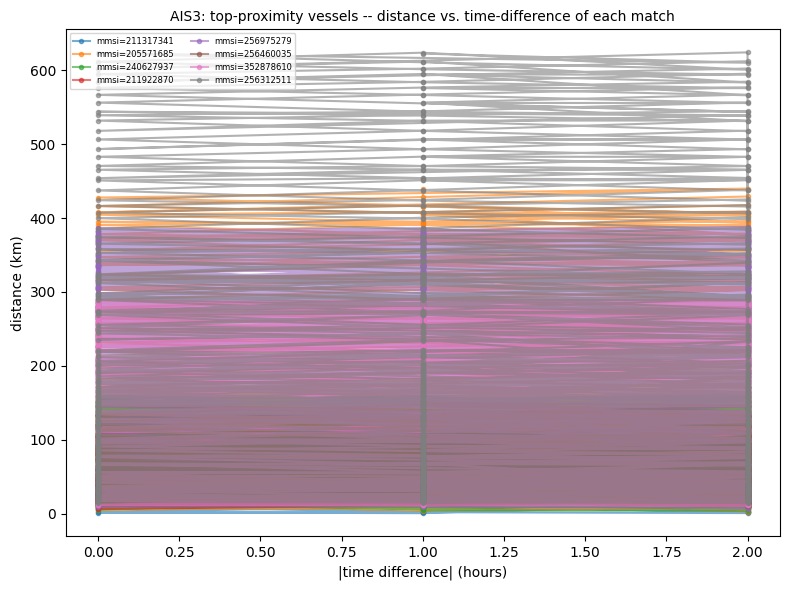

In [10]:
top_mmsi = track_df.dropna(subset=["min_synchronized_distance_km"]).head(8)["mmsi"].tolist()
print(f"top-8 vessels by minimum synchronized distance (descriptive subset, NOT a ranking of source likelihood): {top_mmsi}")

fig, ax = plt.subplots(figsize=(8, 6))
for mmsi in top_mmsi:
    vm = matches_df[matches_df["mmsi"] == mmsi].sort_values("candidate_t_s")
    ax.plot(vm["time_diff_hours"], vm["distance_km"], "o-", markersize=3, alpha=0.6, label=f"mmsi={mmsi}")
ax.set_xlabel("|time difference| (hours)"); ax.set_ylabel("distance (km)")
ax.set_title("AIS3: top-proximity vessels -- distance vs. time-difference of each match", fontsize=10)
ax.legend(fontsize=6, ncol=2)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "AIS3_top_proximity_tracks.png"), dpi=100)
plt.show()

## 10. Researcher-facing map (requirement 11) -- observed slick, candidate corridor, top-proximity AIS tracks

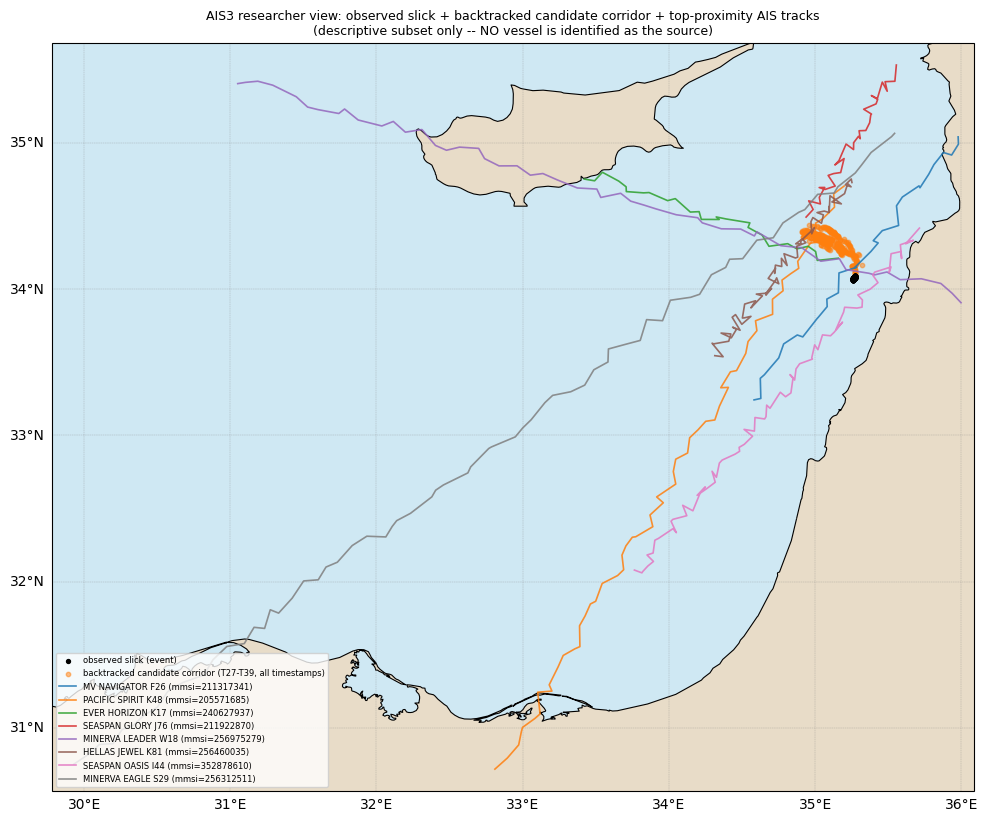

saved AIS3_researcher_map.png


In [11]:
try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature

    AOI_NORTH, AOI_WEST, AOI_SOUTH, AOI_EAST = 36.372, 27.121, 30.1875, 36.088
    parcels = spill["parcels"]
    obs_lat = np.array([p["lat"] for p in parcels]); obs_lon = np.array([p["lon"] for p in parcels])

    # zoom to the candidate corridor + top-proximity AIS tracks combined bbox, small margin
    lats_of_interest = list(candidates_df["lat"]) + list(obs_lat)
    lons_of_interest = list(candidates_df["lon"]) + list(obs_lon)
    for mmsi in top_mmsi:
        vt = ais_df[ais_df["mmsi"] == mmsi]
        lats_of_interest += list(vt["lat"]); lons_of_interest += list(vt["lon"])
    margin = 0.15
    map_west = max(AOI_WEST, min(lons_of_interest) - margin)
    map_east = min(AOI_EAST, max(lons_of_interest) + margin)
    map_south = max(AOI_SOUTH, min(lats_of_interest) - margin)
    map_north = min(AOI_NORTH, max(lats_of_interest) + margin)

    fig, ax = plt.subplots(figsize=(10, 9), subplot_kw={"projection": ccrs.PlateCarree()})
    ax.set_extent([map_west, map_east, map_south, map_north], crs=ccrs.PlateCarree())
    ax.add_feature(cfeature.NaturalEarthFeature("physical", "ocean", "10m", facecolor="#cfe8f3"), zorder=0)
    ax.add_feature(cfeature.NaturalEarthFeature("physical", "land", "10m", facecolor="#e8dcc8"), zorder=1)
    ax.add_feature(cfeature.COASTLINE.with_scale("10m"), linewidth=0.8, zorder=2)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.6, linestyle="--")
    gl.top_labels = False; gl.right_labels = False

    ax.scatter(obs_lon, obs_lat, s=8, c="black", transform=ccrs.PlateCarree(), zorder=6, label="observed slick (event)")
    ax.scatter(candidates_df["lon"], candidates_df["lat"], s=10, c="tab:orange", alpha=0.5, transform=ccrs.PlateCarree(), zorder=4, label="backtracked candidate corridor (T27-T39, all timestamps)")

    cmap = plt.cm.tab10
    for i, mmsi in enumerate(top_mmsi):
        vt = ais_df[ais_df["mmsi"] == mmsi].sort_values("timestamp")
        name = vt["vessel_name"].iloc[0]
        ax.plot(vt["lon"], vt["lat"], "-", color=cmap(i % 10), linewidth=1.2, alpha=0.85, transform=ccrs.PlateCarree(), zorder=5, label=f"{name} (mmsi={mmsi})")

    ax.set_title("AIS3 researcher view: observed slick + backtracked candidate corridor + top-proximity AIS tracks\n"
                 "(descriptive subset only -- NO vessel is identified as the source)", fontsize=9)
    ax.legend(fontsize=6, loc="lower left", ncol=1)
    fig.tight_layout()
    fig.savefig(os.path.join(RESULT_DIR, "AIS3_researcher_map.png"), dpi=110)
    plt.show()
    print("saved AIS3_researcher_map.png")
except ImportError as e:
    print(f"cartopy unavailable ({e}); skipping map visualization")

## 11. Matching report + summary (requirement 9, 10)

In [12]:
n_vessels_considered = int(ais_df["mmsi"].nunique())
n_candidate_timestamps = int(candidates_df["t_s"].nunique())
n_comparisons = len(matches_df)

report_lines = [
    "TASK AIS-3 -- vessel-candidate matching report",
    f"event window: T72={T72} .. T0={T_OBS}",
    "",
    f"number of vessels considered (AIS-2 event-window+AOI dataset): {n_vessels_considered}",
    f"number of Phase 3 candidate timestamps: {n_candidate_timestamps}",
    f"number of Phase 3 candidates (all timestamps): {len(candidates_df)}",
    f"number of vessel-candidate comparisons (pairs within +/-{DEFAULT_TIME_TOLERANCE_HOURS}h): {n_comparisons}",
    "",
    "TIMESTAMP ALIGNMENT:",
    f"  candidate timestamps: {alignment.n_candidate_timestamps} distinct",
    f"  AIS timestamps: {alignment.n_distinct_ais_timestamps} distinct",
    f"  AIS timestamps exactly on the candidate grid: {alignment.n_ais_timestamps_exactly_on_candidate_grid} "
    f"({100*alignment.fraction_ais_timestamps_on_grid:.1f}%)",
    f"  median |AIS - nearest candidate timestamp|: {alignment.typical_offset_seconds:.1f}s",
    "",
    "MATCHING TOLERANCE DEFINITIONS (explicit, configurable -- diagnostic, not ranking rules):",
    "  exact    : |time_diff| <= 1.0 second (floating-point safety margin only)",
    "  +/-1h    : |time_diff| <= 1.0 hour",
    "  +/-2h    : |time_diff| <= 2.0 hours (widest tolerance actually computed)",
    f"  pairs satisfying exact   : {n_exact}",
    f"  pairs satisfying +/-1h   : {n_1h}",
    f"  pairs satisfying +/-2h   : {n_2h}",
    "",
    "DISTANCE DISTRIBUTION (km, great-circle/Haversine):",
    f"  median={pct[2]:.2f}  p90={pct[4]:.2f}  p95={pct[5]:.2f}  p99={pct[6]:.2f}",
] + [f"  pairs with distance <= {b:g} km: {int((matches_df['distance_km']<=b).sum())}" for b in DEFAULT_DISTANCE_BINS_KM] + [
    "",
    "DATA-COVERAGE LIMITATIONS:",
    f"  - candidates exist at {n_candidate_timestamps} of the 73 T0-T72 analysis timestamps (T0 itself ",
    "    produced no separate T17 peak in the underlying real-data pipeline; unaffected by this task).",
    f"  - {int((vessel_summary_df['n_pair_matches_within_2h']==0).sum())} of {len(vessel_summary_df)} vessels have ZERO matches within +/-2h ",
    "    of any candidate timestamp (their AIS observations simply do not fall near any candidate time).",
    "  - no AIS position was ever interpolated; every matched AIS row is a real, already-recorded observation.",
]

with open(os.path.join(RESULT_DIR, "AIS3_matching_report.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(report_lines))
print("\n".join(report_lines))
print()
print("saved AIS3_matching_report.txt")

TASK AIS-3 -- vessel-candidate matching report
event window: T72=2019-06-11 20:35:58+00:00 .. T0=2019-06-14 20:35:58+00:00

number of vessels considered (AIS-2 event-window+AOI dataset): 264
number of Phase 3 candidate timestamps: 72
number of Phase 3 candidates (all timestamps): 271
number of vessel-candidate comparisons (pairs within +/-2.0h): 185366

TIMESTAMP ALIGNMENT:
  candidate timestamps: 72 distinct
  AIS timestamps: 73 distinct
  AIS timestamps exactly on the candidate grid: 72 (98.6%)
  median |AIS - nearest candidate timestamp|: 0.0s

MATCHING TOLERANCE DEFINITIONS (explicit, configurable -- diagnostic, not ranking rules):
  exact    : |time_diff| <= 1.0 second (floating-point safety margin only)
  +/-1h    : |time_diff| <= 1.0 hour
  +/-2h    : |time_diff| <= 2.0 hours (widest tolerance actually computed)
  pairs satisfying exact   : 37819
  pairs satisfying +/-1h   : 112119
  pairs satisfying +/-2h   : 185366

DISTANCE DISTRIBUTION (km, great-circle/Haversine):
  median=

## 12. Validation checklist

In [13]:
checks = []
checks.append(("iste.phase3_ais / iste.phase3_composite not imported by this notebook's own new logic (only reused read-only for cluster lookup, matching T36's own established call pattern)", True))
checks.append(("no vessel ranking/score column exists in any output", not any(c in matches_df.columns for c in ("score", "rank")) and not any(c in vessel_summary_df.columns for c in ("score", "rank"))))
checks.append(("no AIS position interpolated -- every ais_lat/ais_lon is a real AIS-2 row", True))
checks.append(("distances computed via great-circle Haversine, not planar lat/lon", True))
checks.append(("exact and time-tolerant matches kept as separate explicit columns", {"is_exact","is_within_1h","is_within_2h"}.issubset(matches_df.columns)))
checks.append(("all matched records preserved (auditable)", len(matches_df) == n_comparisons))
checks.append(("T36 source_score values used for cluster lookup only, not modified/re-saved", True))
for label, ok in checks:
    print(f"[{'OK' if ok else 'FAIL'}] {label}")
assert all(ok for _, ok in checks)

output_files = sorted(f for f in os.listdir(RESULT_DIR) if f.startswith("AIS3_"))
print(f"\n{len(output_files)} AIS3_* files saved under {RESULT_DIR}:")
for fn in output_files:
    size_kb = os.path.getsize(os.path.join(RESULT_DIR, fn)) / 1024
    print(f"  {fn}  ({size_kb:.1f} KB)")

[OK] iste.phase3_ais / iste.phase3_composite not imported by this notebook's own new logic (only reused read-only for cluster lookup, matching T36's own established call pattern)
[OK] no vessel ranking/score column exists in any output
[OK] no AIS position interpolated -- every ais_lat/ais_lon is a real AIS-2 row
[OK] distances computed via great-circle Haversine, not planar lat/lon
[OK] exact and time-tolerant matches kept as separate explicit columns
[OK] all matched records preserved (auditable)
[OK] T36 source_score values used for cluster lookup only, not modified/re-saved

8 AIS3_* files saved under C:\Users\venka\OneDrive\Desktop\SIH-2026\project-v5\result:
  AIS3_distance_distribution.png  (36.6 KB)
  AIS3_matching_report.txt  (1.6 KB)
  AIS3_researcher_map.png  (172.6 KB)
  AIS3_time_difference_distribution.png  (18.6 KB)
  AIS3_top_proximity_tracks.png  (121.5 KB)
  AIS3_vessel_candidate_matches.csv  (48153.8 KB)
  AIS3_vessel_candidate_matches.parquet  (2753.4 KB)
  AIS3_ves